# 2 · La méthode des éléments finis en 1D : de « barre = ressort » à $\mathbf K\mathbf u=\mathbf f$

*Notebook 2 du cours. Suite du [notebook 1](01_discretisation.ipynb) (découpage en boîtes). Aucun prérequis de mécanique.*

Le notebook 1 a expliqué **où** vivent les inconnues (densités dans les boîtes, déplacements aux coins). Il reste à répondre à : **comment calcule-t-on ces déplacements ?** Toute la mécanique du projet repose sur un système linéaire

$$\mathbf K\,\mathbf u=\mathbf f,$$

où $\mathbf u$ contient les déplacements des nœuds, $\mathbf f$ les forces appliquées et $\mathbf K$ est la **matrice de rigidité**. Pour comprendre d'où elle sort, on commence par le cas le plus simple possible : **une barre qu'on étire**. Tout ce qui est vu ici (assemblage, conditions aux limites, convergence) reste vrai, à l'identique, en 2D et en 3D.

**Plan.**
1. Des ressorts en série : on construit $\mathbf K$ à la main.
2. Pourquoi une barre est un ressort, et ce que signifie « équilibre » (énergie).
3. L'élément de barre et son assemblage (version lisible, puis version vectorisée).
4. Imposer un appui ; vérifier contre la solution exacte.
5. Convergence : de combien l'erreur diminue quand on raffine ?
6. Une barre dont la rigidité varie d'un élément à l'autre, et la **compliance**.
7. Un premier avant-goût de l'optimisation : où mettre la matière ?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=110)

## 1. Des ressorts en série

Un ressort de raideur $k$ (en N/m) relie deux points. S'il est étiré de $\Delta$, il exerce la force $k\,\Delta$ (loi de Hooke). Prenons **trois ressorts alignés** reliant 4 nœuds numérotés $0,1,2,3$. Chaque nœud $i$ a un déplacement $u_i$ et reçoit une force extérieure $f_i$.

Pour **un** ressort entre les nœuds $i$ et $i+1$, avec $\Delta=u_{i+1}-u_i$, les forces qu'il exerce sur ses deux extrémités sont :

$$
\begin{pmatrix}F_i\\F_{i+1}\end{pmatrix}
=\underbrace{k\begin{pmatrix}1&-1\\-1&1\end{pmatrix}}_{\mathbf k_e}
\begin{pmatrix}u_i\\u_{i+1}\end{pmatrix}.
$$

(Le signe $-$ traduit l'action–réaction : si le ressort tire un nœud vers la droite, il tire l'autre vers la gauche.)

À chaque nœud, **la somme des forces des ressorts qui le touchent doit équilibrer la force extérieure**. Écrire cela pour tous les nœuds revient à *additionner* les petites matrices $\mathbf k_e$ aux bons endroits : c'est l'**assemblage**.

In [2]:
def assembler_ressorts(k):
    # k : liste des raideurs ; le ressort e relie les nœuds e et e+1.
    n_noeuds = len(k) + 1
    K = np.zeros((n_noeuds, n_noeuds))
    for e, ke in enumerate(k):
        K[e:e + 2, e:e + 2] += ke * np.array([[1.0, -1.0], [-1.0, 1.0]])   # on AJOUTE : un nœud est partagé
    return K

k = [2.0, 1.0, 4.0]              # trois ressorts, raideurs en N/m
K = assembler_ressorts(k)
print("K =\n", K)
print("\nvaleurs propres :", np.linalg.eigvalsh(K))

K =
 [[ 2. -2.  0.  0.]
 [-2.  3. -1.  0.]
 [ 0. -1.  5. -4.]
 [ 0.  0. -4.  4.]]

valeurs propres : [0.     0.8153 4.5409 8.6438]


Deux observations importantes.

- **$\mathbf K$ est tridiagonale** : un nœud n'interagit qu'avec ses voisins immédiats. Ce caractère *creux* sera crucial en 2D/3D.
- **Elle a une valeur propre nulle** : $\mathbf K$ n'est pas inversible. Physiquement, si rien n'est attaché, la chaîne entière peut *se translater* sans aucun effort (mouvement de corps rigide). Le système $\mathbf K\mathbf u=\mathbf f$ n'a alors pas de solution unique. Il faut **bloquer** au moins un nœud, ce qui s'appelle imposer une **condition aux limites**.

Bloquons le nœud 0 (« mur à gauche ») et tirons le nœud 3 avec une force de 10 N. On retire simplement la ligne et la colonne 0 :

In [3]:
f = np.array([0.0, 0.0, 0.0, 10.0])          # 10 N sur le dernier nœud
libres = [1, 2, 3]                              # le nœud 0 est bloqué : u_0 = 0
u = np.zeros(4)
u[libres] = np.linalg.solve(K[np.ix_(libres, libres)], f[libres])
print("déplacements u =", u)

# Vérification à la main : ressorts en série => les allongements s'additionnent, chacun vaut F/k
print("attendu       u =", np.cumsum([0, 10 / 2.0, 10 / 1.0, 10 / 4.0]))

déplacements u = [ 0.   5.  15.  17.5]
attendu       u = [ 0.   5.  15.  17.5]


## 2. Une barre est un ressort ; l'équilibre est un minimum d'énergie

Une barre de section $A$, de module d'Young $E$ et de longueur $L$, tirée par une force $F$ s'allonge de $\Delta = \dfrac{F\,L}{E A}$. C'est donc un ressort de raideur

$$k_{\text{barre}}=\frac{EA}{L}.$$

**Découper la barre en $n$ éléments** de longueur $h=L/n$ revient à la voir comme $n$ ressorts en série de raideur $EA/h$ chacun. Raideur équivalente : $1\big/\big(n\,\tfrac{h}{EA}\big)=\tfrac{EA}{L}$, identique. Le raisonnement du §1 s'applique donc tel quel ; on verra plus bas en quoi la discrétisation introduit tout de même une approximation (quand la charge ou la rigidité varient).

**Pourquoi $\mathbf K\mathbf u=\mathbf f$ ? Le point de vue énergétique.** Pour des déplacements $\mathbf u$ quelconques, l'énergie potentielle de la structure est

$$\Pi(\mathbf u)=\underbrace{\tfrac12\,\mathbf u^\top\mathbf K\,\mathbf u}_{\text{énergie de déformation}}\;-\;\underbrace{\mathbf f^\top\mathbf u}_{\text{travail des forces}} .$$

La structure se place là où $\Pi$ est **minimale**, c'est-à-dire où son gradient s'annule : $\mathbf K\mathbf u-\mathbf f=\mathbf 0$. Avec un seul ressort, on le voit directement :

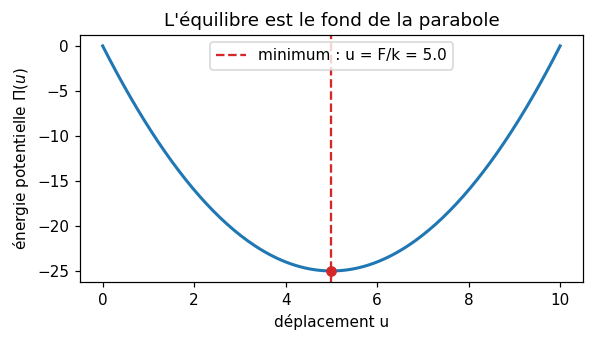

In [4]:
k_, F_ = 2.0, 10.0
u_grid = np.linspace(0, 10, 200)
Pi = 0.5 * k_ * u_grid ** 2 - F_ * u_grid

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(u_grid, Pi, lw=2)
ax.axvline(F_ / k_, color="C3", ls="--", label=f"minimum : u = F/k = {F_ / k_:.1f}")
ax.plot(F_ / k_, 0.5 * k_ * (F_ / k_) ** 2 - F_ * F_ / k_, "C3o")
ax.set_xlabel("déplacement u"); ax.set_ylabel(r"énergie potentielle $\Pi(u)$")
ax.set_title("L'équilibre est le fond de la parabole"); ax.legend()
plt.tight_layout(); plt.show()

Trois conséquences qui reviendront tout au long du projet :

1. $\mathbf K$ doit être **symétrique définie positive (SPD)** (une fois la structure bloquée) pour que $\Pi$ ait un unique minimum : c'est ce qui autorise les solveurs rapides (Cholesky, gradient conjugué).
2. À l'équilibre, $\mathbf u^\top\mathbf K\mathbf u=\mathbf f^\top\mathbf u$, donc $\Pi=-\tfrac12\,\mathbf f^\top\mathbf u$. La quantité **$\mathcal C=\mathbf f^\top\mathbf u$** s'appelle la **compliance** : c'est le double de l'énergie de déformation. *Plus la compliance est petite, plus la structure est rigide sous cette charge.* C'est l'objectif mécanique du projet.
3. Une valeur propre nulle de $\mathbf K$ = un mouvement sans énergie (corps rigide) = une condition aux limites manquante.

## 3. L'élément de barre : matrice de rigidité et assemblage

Dans un élément de longueur $h$, on suppose que le déplacement varie **linéairement** entre ses deux nœuds (ce sont les fonctions de forme Q1 du notebook 1, en 1D) :
$u(x)=N_0(x)\,u_0+N_1(x)\,u_1$, avec $N_0=1-\tfrac{x}{h}$ et $N_1=\tfrac{x}{h}$.
La déformation (allongement relatif) est alors constante dans l'élément :

$$\varepsilon=\frac{du}{dx}=\frac{u_1-u_0}{h}=\underbrace{\Big(-\tfrac1h\;\;\tfrac1h\Big)}_{\mathbf B}\begin{pmatrix}u_0\\u_1\end{pmatrix},$$

et l'énergie de déformation de l'élément est $\tfrac12\int_0^h EA\,\varepsilon^2\,dx=\tfrac12\,\mathbf u_e^\top\,(EA\,h\,\mathbf B^\top\mathbf B)\,\mathbf u_e$. D'où la matrice élémentaire

$$\mathbf K_e=EA\,h\,\mathbf B^\top\mathbf B=\frac{EA}{h}\begin{pmatrix}1&-1\\-1&1\end{pmatrix}.$$

On retrouve la matrice d'un ressort de raideur $EA/h$, mais cette fois **par un calcul** (intégrale de $\mathbf B^\top E\,\mathbf B$) qui se généralise tel quel en 2D et 3D : c'est exactement ce qu'on fera au notebook 3.

### Assemblage, version lisible

Le nœud $i$ est partagé par les éléments $i-1$ et $i$ : il reçoit les contributions des deux.

In [5]:
def Ke_barre(EA, h):
    return EA / h * np.array([[1.0, -1.0], [-1.0, 1.0]])

def assembler_boucle(EA_e, h):
    # EA_e : rigidité EA de chaque élément (tableau de taille n) ; h : longueur d'un élément.
    n = len(EA_e)
    K = np.zeros((n + 1, n + 1))
    for e in range(n):                           # on parcourt les éléments un par un
        K[e:e + 2, e:e + 2] += Ke_barre(EA_e[e], h)
    return K

print((assembler_boucle(np.ones(5), 1.0)))

[[ 1. -1.  0.  0.  0.  0.]
 [-1.  2. -1.  0.  0.  0.]
 [ 0. -1.  2. -1.  0.  0.]
 [ 0.  0. -1.  2. -1.  0.]
 [ 0.  0.  0. -1.  2. -1.]
 [ 0.  0.  0.  0. -1.  1.]]


### Assemblage, version vectorisée (celle du projet)

Une boucle Python est trop lente dès qu'il y a des milliers d'éléments. On remplace la boucle par trois opérations sur des tableaux entiers :

1. **Gather (rassembler)** : pour chaque élément, la liste de ses numéros de nœuds (`conn`, de forme `(n, 2)`), obtenue par simple arithmétique comme au notebook 1.
2. **Calcul groupé** : toutes les matrices élémentaires d'un coup, un tableau de forme `(n, 2, 2)`.
3. **Scatter-add (disperser en additionnant)** : on ajoute chaque coefficient élémentaire à sa case $(\text{ligne},\text{colonne})$ de $\mathbf K$.

Le point délicat est le « additionnant » : un même coefficient global reçoit plusieurs contributions. L'affectation NumPy ordinaire `K[lignes, colonnes] += valeurs` **n'additionne pas** les indices répétés ; il faut `np.add.at` (en PyTorch : `index_add_`).

In [6]:
def assembler_vectorise(EA_e, h):
    EA_e = np.asarray(EA_e, dtype=float)
    n = len(EA_e)
    conn = np.arange(n)[:, None] + np.array([0, 1])                  # gather : (n, 2), nœuds de chaque élément
    Ke = (EA_e / h)[:, None, None] * np.array([[1.0, -1.0], [-1.0, 1.0]])   # (n, 2, 2) : une matrice par élément
    lignes = np.repeat(conn, 2, axis=1).ravel()                      # [c0 c0 c1 c1] pour chaque élément
    colonnes = np.tile(conn, (1, 2)).ravel()                         # [c0 c1 c0 c1]
    K = np.zeros((n + 1, n + 1))
    np.add.at(K, (lignes, colonnes), Ke.reshape(n, 4).ravel())       # scatter-add
    return K, (lignes, colonnes, Ke.reshape(n, 4).ravel())

EA_test = np.array([3.0, 1.0, 2.0, 5.0, 4.0, 1.0])
K1 = assembler_boucle(EA_test, 0.5)
K2, (L_, C_, V_) = assembler_vectorise(EA_test, 0.5)
print("boucle == vectorisé :", np.allclose(K1, K2))

# Le piège : l'affectation « += » classique ignore les doublons.
K_faux = np.zeros_like(K1)
K_faux[L_, C_] += V_
print("avec  K[l, c] += v  :", np.allclose(K1, K_faux), "(les contributions partagées sont perdues)")
print("écart maximal       :", np.abs(K1 - K_faux).max())

boucle == vectorisé : True
avec  K[l, c] += v  : False (les contributions partagées sont perdues)
écart maximal       : 10.0


## 4. Imposer un appui, résoudre et vérifier

Au §1 on a supprimé les lignes/colonnes des nœuds bloqués. Le solveur du projet utilise une autre écriture, équivalente mais plus pratique pour une implémentation vectorisée : on **garde la taille du système** et on remplace les équations bloquées par « $u_i=0$ ».

Avec $\mathbf P$ la matrice diagonale valant 1 sur les ddl libres et 0 sur les ddl bloqués :

$$\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P),\qquad \widetilde{\mathbf K}\,\mathbf u=\mathbf P\,\mathbf f.$$

$\mathbf P\mathbf K\mathbf P$ efface lignes et colonnes bloquées, et $(\mathbf I-\mathbf P)$ y met des 1 sur la diagonale. Résultat : une matrice **SPD de même taille**, dont la solution vérifie $u_i=0$ sur les ddl bloqués.

**Banc d'essai.** Une barre en PLA de $L=100$ mm, section $10\times10$ mm$^2$ ($E=2$ GPa), encastrée à gauche.

In [7]:
def resoudre(K, f, bloques):
    N = len(f)
    libre = np.ones(N)
    libre[bloques] = 0.0
    P = np.diag(libre)
    Kt = P @ K @ P + (np.eye(N) - P)           # identité sur les ddl bloqués
    assert np.linalg.eigvalsh(Kt).min() > 0, "K tilde doit être définie positive"
    return np.linalg.solve(Kt, P @ f)

# --- données physiques (SI) ---
L, A, E = 0.100, 1.0e-4, 2.0e9
EA = E * A                                     # 2.10^5 N

# --- Cas A : force F en bout de barre ---
F = 100.0
n = 5; h = L / n
K, _ = assembler_vectorise(np.full(n, EA), h)
f = np.zeros(n + 1); f[-1] = F
u = resoudre(K, f, bloques=[0])
x_noeuds = np.linspace(0, L, n + 1)
u_exact = F * x_noeuds / EA
print("u (FEM)   [mm] :", u * 1e3)
print("u (exact) [mm] :", u_exact * 1e3)
print("erreur relative maximale :", np.abs(u - u_exact).max() / u_exact.max())

u (FEM)   [mm] : [0.   0.01 0.02 0.03 0.04 0.05]
u (exact) [mm] : [0.   0.01 0.02 0.03 0.04 0.05]
erreur relative maximale : 1.3552527156068805e-16


La solution est **exacte** aux nœuds (à l'erreur machine près), même avec 5 éléments : sous une force en bout, le déplacement exact est linéaire, et les fonctions de forme linéaires le représentent parfaitement.

**Cas B : charge répartie** (par exemple le poids propre, ou une pression), $q$ N/m le long de la barre. Le déplacement exact est alors **parabolique**, $u(x)=\dfrac{q\,(Lx-x^2/2)}{EA}$, et un élément linéaire ne peut plus le suivre exactement. Les forces réparties sont converties en forces nodales : chaque élément donne $q\,h/2$ à chacun de ses deux nœuds.

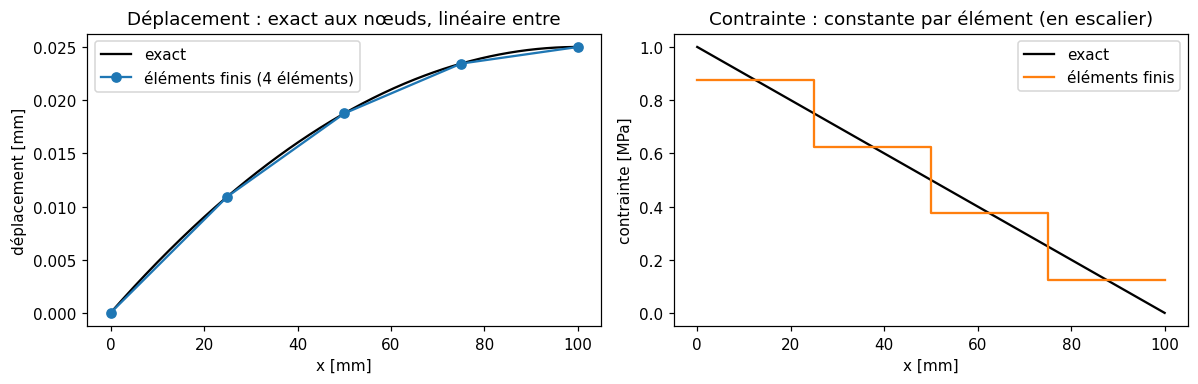

erreur max aux nœuds : 2.7105054312137606e-16


In [8]:
def resoudre_barre_repartie(n, q=1000.0):
    h = L / n
    K, _ = assembler_vectorise(np.full(n, EA), h)
    f = np.zeros(n + 1)
    f[:-1] += q * h / 2                          # moitié de la charge de chaque élément
    f[1:] += q * h / 2
    return resoudre(K, f, bloques=[0])

q = 1000.0                                       # N/m  (100 N au total)
ue = lambda x: q * (L * x - x ** 2 / 2) / EA     # solution exacte
se = lambda x: q * (L - x) / A                   # contrainte exacte sigma = E u' = q (L - x) / A  [Pa]

n = 4
u = resoudre_barre_repartie(n, q)
xs = np.linspace(0, L, 400)
xn = np.linspace(0, L, n + 1)
sigma_el = E * np.diff(u) / (L / n)              # contrainte constante dans chaque élément

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(xs * 1e3, ue(xs) * 1e3, "k", label="exact")
axs[0].plot(xn * 1e3, u * 1e3, "o-", label=f"éléments finis ({n} éléments)")
axs[0].set_xlabel("x [mm]"); axs[0].set_ylabel("déplacement [mm]"); axs[0].legend()
axs[0].set_title("Déplacement : exact aux nœuds, linéaire entre")
axs[1].plot(xs * 1e3, se(xs) / 1e6, "k", label="exact")
axs[1].step(np.repeat(xn, 2)[1:-1] * 1e3, np.repeat(sigma_el, 2) / 1e6, "C1", label="éléments finis")
axs[1].set_xlabel("x [mm]"); axs[1].set_ylabel("contrainte [MPa]"); axs[1].legend()
axs[1].set_title("Contrainte : constante par élément (en escalier)")
plt.tight_layout(); plt.show()
print("erreur max aux nœuds :", np.abs(u - ue(xn)).max() / ue(L))

Deux faits à retenir :

- Le déplacement est **plus précis que sa dérivée**. Ici il est même exact aux nœuds (propriété particulière du 1D) ; la contrainte, elle, est une dérivée de $u$, donc **constante par élément**, avec des sauts aux interfaces. En 2D/3D, les champs de contrainte sont de même *moins précis* que ceux de déplacement.
- La valeur de la contrainte d'un élément est exacte *en son milieu* ; l'erreur se voit sur les bords. On le quantifie ci-dessous.

## 5. Convergence : de combien l'erreur diminue-t-elle quand on raffine ?

Doublons le nombre d'éléments plusieurs fois et mesurons l'erreur, pour le déplacement entre les nœuds et pour la contrainte.

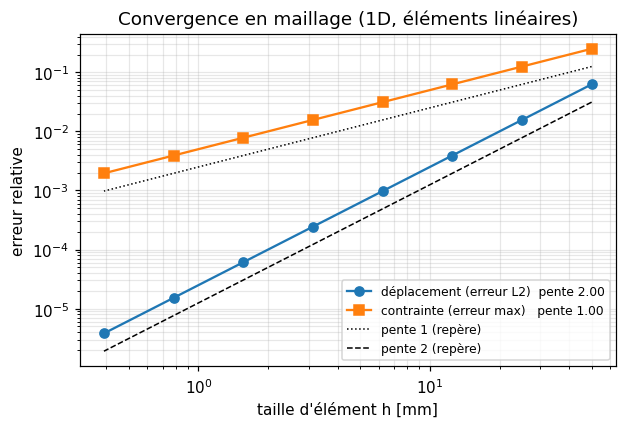

pente déplacement : 2.00  (théorie : 2)
pente contrainte  : 1.00  (théorie : 1)


In [9]:
xs = np.linspace(0, L, 4001)
ns = np.array([2, 4, 8, 16, 32, 64, 128, 256])
err_u, err_s = [], []
for n in ns:
    h = L / n
    u = resoudre_barre_repartie(n, q)
    uh = np.interp(xs, np.linspace(0, L, n + 1), u)                  # déplacement interpolé (linéaire par morceaux)
    e_idx = np.minimum((xs / h).astype(int), n - 1)                  # élément contenant chaque point
    sh = (E * np.diff(u) / h)[e_idx]                                 # contrainte FEM (constante par élément)
    err_u.append(np.sqrt(np.mean((uh - ue(xs)) ** 2)) / np.sqrt(np.mean(ue(xs) ** 2)))
    err_s.append(np.abs(sh - se(xs)).max() / se(0.0))

hs = L / ns
pente_u = np.polyfit(np.log(hs), np.log(err_u), 1)[0]
pente_s = np.polyfit(np.log(hs), np.log(err_s), 1)[0]

fig, ax = plt.subplots(figsize=(5.8, 4))
ax.loglog(hs * 1e3, err_u, "o-", label=f"déplacement (erreur L2)  pente {pente_u:.2f}")
ax.loglog(hs * 1e3, err_s, "s-", label=f"contrainte (erreur max)   pente {pente_s:.2f}")
ax.loglog(hs * 1e3, 0.5 * err_s[0] * (hs / hs[0]), "k:", lw=1, label="pente 1 (repère)")
ax.loglog(hs * 1e3, 0.5 * err_u[0] * (hs / hs[0]) ** 2, "k--", lw=1, label="pente 2 (repère)")
ax.set_xlabel("taille d'élément h [mm]"); ax.set_ylabel("erreur relative")
ax.legend(fontsize=8); ax.grid(which="both", alpha=0.3)
ax.set_title("Convergence en maillage (1D, éléments linéaires)")
plt.tight_layout(); plt.show()
print(f"pente déplacement : {pente_u:.2f}  (théorie : 2)")
print(f"pente contrainte  : {pente_s:.2f}  (théorie : 1)")

**Ordre de convergence.** Diviser $h$ par 2 divise l'erreur sur les déplacements par 4 (ordre 2) et celle sur les contraintes par 2 (ordre 1). C'est le comportement attendu des éléments linéaires (Q1 en 2D/3D se comporte de même sur des solutions lisses). Une courbe d'erreur de pente connue est un outil de **validation** très utile : si un jour le code d'assemblage 2D est faux, la pente ne sera pas la bonne.

## 6. Une rigidité qui varie d'un élément à l'autre ; la compliance

Jusqu'ici tous les éléments avaient la même rigidité $EA$. Rien n'empêche d'en donner une **différente à chaque élément** : l'assemblage du §3 le permettait déjà (`EA_e` est un tableau). C'est précisément ce que fera l'optimisation topologique : *le module d'Young de chaque boîte sera proportionnel à sa densité* (le SIMP, leçon 8).

Prenons une barre de 20 éléments, tirée en bout par $F=100$ N, dont 4 éléments centraux sont 5 fois plus mous (par exemple un trou d'allègement partiel).

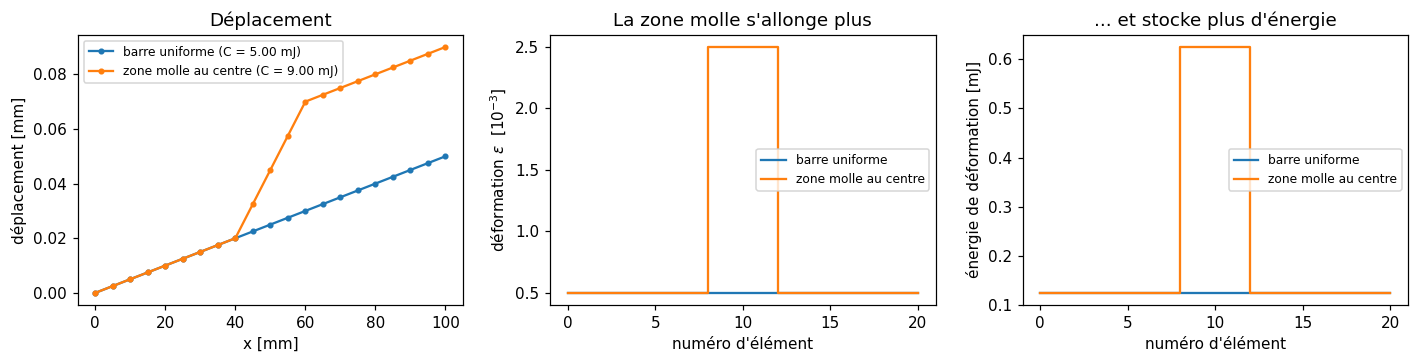

In [10]:
n = 20; h = L / n; F = 100.0
facteur = np.ones(n); facteur[8:12] = 0.2            # 4 éléments à 20 % de la rigidité
cas = {"barre uniforme": np.ones(n), "zone molle au centre": facteur}

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for nom, fac in cas.items():
    EA_e = EA * fac
    K, _ = assembler_vectorise(EA_e, h)
    f = np.zeros(n + 1); f[-1] = F
    u = resoudre(K, f, bloques=[0])
    eps = np.diff(u) / h                              # déformation de chaque élément
    energie = 0.5 * EA_e * eps ** 2 * h               # énergie de déformation de chaque élément
    C = f @ u                                         # compliance
    assert np.isclose(C, 2 * energie.sum())           # compliance = 2 x énergie totale
    assert np.isclose(C, u @ K @ u)                   # = u^T K u
    axs[0].plot(np.linspace(0, L, n + 1) * 1e3, u * 1e3, "o-", ms=3, label=f"{nom} (C = {C * 1e3:.2f} mJ)")
    axs[1].step(np.arange(n + 1), np.r_[eps, eps[-1]] * 1e3, where="post", label=nom)
    axs[2].step(np.arange(n + 1), np.r_[energie, energie[-1]] * 1e3, where="post", label=nom)
axs[0].set_xlabel("x [mm]"); axs[0].set_ylabel("déplacement [mm]"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("numéro d'élément"); axs[1].set_ylabel(r"déformation $\varepsilon$  [10$^{-3}$]")
axs[2].set_xlabel("numéro d'élément"); axs[2].set_ylabel("énergie de déformation [mJ]")
for ax in axs[1:]:
    ax.legend(fontsize=8)
axs[0].set_title("Déplacement"); axs[1].set_title("La zone molle s'allonge plus"); axs[2].set_title("... et stocke plus d'énergie")
plt.tight_layout(); plt.show()

La zone molle s'allonge davantage, donc le bout de la barre se déplace plus : la **compliance augmente** (la barre est moins rigide). Les deux identités vérifiées dans la cellule (`C = 2 × énergie = uᵀKu`) sont celles que le projet utilisera comme tests.

## 7. Un avant-goût de l'optimisation : où mettre la matière ?

Question : on dispose d'une quantité **fixée** de matière (la moitié de ce qu'il faudrait pour remplir la barre) ; comment la répartir pour que la barre soit la plus rigide possible sous une charge répartie $q$ ?

On pose $EA_e=\rho_e\,EA$, où $\rho_e\in[0,1]$ est la « densité » de l'élément, avec la contrainte $\sum_e\rho_e=0{,}5\,n$ (matière fixée).

Dans cette barre, l'effort normal $N_e$ dans chaque élément est imposé par l'équilibre seul (il est égal à la charge située au-delà de l'élément) : $N_e\approx q\,(L-x_e)$. Il **ne dépend pas** de $\rho$. La compliance vaut alors $\mathcal C=\sum_e N_e^2\,h/(EA\,\rho_e)$. En minimisant avec la contrainte de matière (multiplicateur de Lagrange), on trouve :

$$\rho_e\;\propto\;N_e,$$

c'est-à-dire **de la matière là où passe l'effort**. Comparons une répartition uniforme et cette répartition « optimale », en calculant les deux par éléments finis, puis testons 3000 répartitions aléatoires de même masse.

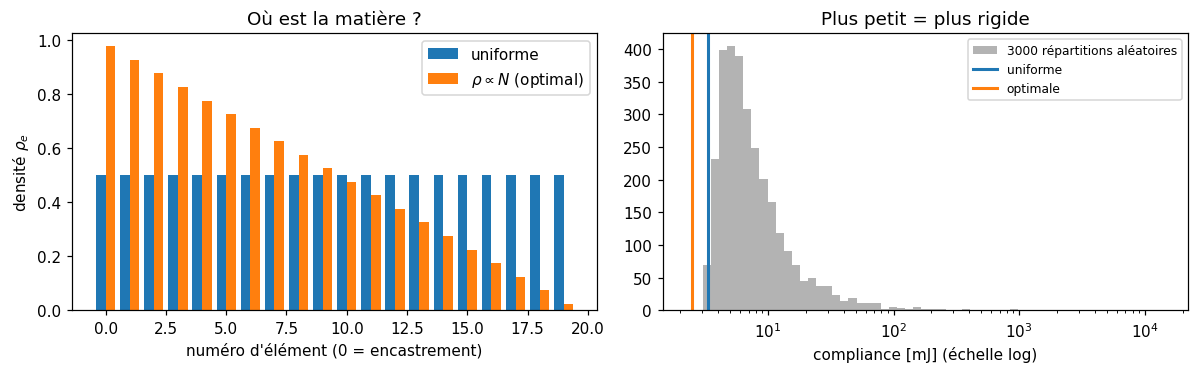

compliance uniforme : 3.3313 mJ
compliance optimale : 2.5000 mJ   (25.0 % de moins, à masse égale)
meilleur des 3000 tirages aléatoires : 3.0210 mJ  (aucun ne bat l'optimum : True)


In [11]:
n = 20; h = L / n; q = 1000.0
x_mid = (np.arange(n) + 0.5) * h
N_e = q * (L - x_mid)                                  # effort normal dans chaque élément
V = 0.5 * n                                            # matière disponible : somme des rho = 0.5 n

def compliance(rho):
    K, _ = assembler_vectorise(EA * rho, h)
    f = np.zeros(n + 1); f[:-1] += q * h / 2; f[1:] += q * h / 2
    u = resoudre(K, f, bloques=[0])
    return f @ u

rho_unif = np.full(n, 0.5)
rho_opt = V * N_e / N_e.sum()                          # rho proportionnel à l'effort
assert rho_opt.max() <= 1.0 and np.isclose(rho_opt.sum(), V)

rng = np.random.default_rng(0)
C_alea = []
while len(C_alea) < 3000:
    r = rng.random(n)
    r *= V / r.sum()
    if r.max() <= 1.0:
        C_alea.append(compliance(r))
C_alea = np.array(C_alea)
C_u, C_o = compliance(rho_unif), compliance(rho_opt)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].bar(np.arange(n) - 0.2, rho_unif, 0.4, label="uniforme")
axs[0].bar(np.arange(n) + 0.2, rho_opt, 0.4, label=r"$\rho \propto N$ (optimal)")
axs[0].set_xlabel("numéro d'élément (0 = encastrement)"); axs[0].set_ylabel(r"densité $\rho_e$"); axs[0].legend()
axs[0].set_title("Où est la matière ?")
axs[1].hist(C_alea * 1e3, bins=np.logspace(np.log10(C_o * 1e3 * 0.9), np.log10(C_alea.max() * 1e3), 60), color="0.7", label="3000 répartitions aléatoires")
axs[1].set_xscale("log")
axs[1].axvline(C_u * 1e3, color="C0", lw=2, label="uniforme")
axs[1].axvline(C_o * 1e3, color="C1", lw=2, label="optimale")
axs[1].set_xlabel("compliance [mJ] (échelle log)"); axs[1].legend(fontsize=8)
axs[1].set_title("Plus petit = plus rigide")
plt.tight_layout(); plt.show()
print(f"compliance uniforme : {C_u * 1e3:.4f} mJ")
print(f"compliance optimale : {C_o * 1e3:.4f} mJ   ({100 * (1 - C_o / C_u):.1f} % de moins, à masse égale)")
print(f"meilleur des 3000 tirages aléatoires : {C_alea.min() * 1e3:.4f} mJ  (aucun ne bat l'optimum : {C_alea.min() > C_o})")

À masse égale, la répartition « la matière suit l'effort » est **25 % plus rigide** que la répartition uniforme, et aucun tirage aléatoire ne fait mieux.

**Pourquoi ce cas est trop facile.** Ici $N_e$ ne dépend pas de la répartition de matière (barre isostatique), donc on a pu écrire la solution à la main. Dans une pièce 2D/3D, **les efforts se redistribuent** dès qu'on déplace la matière : la bonne répartition dépend d'elle-même, et il faut un algorithme itératif, guidé par le **gradient** de la compliance par rapport à chaque $\rho_e$ (leçons 7 et 8). Mais l'intuition est la même : de la matière là où l'énergie de déformation est élevée, et rien ailleurs.

## À retenir

| Idée | Où elle réapparaît |
|---|---|
| $\mathbf K=\sum_e \mathbf A_e^\top\mathbf K_e\mathbf A_e$ : on **additionne** des matrices élémentaires à leurs places | assemblage 2D/3D vectorisé (gather → produit dense → scatter-add) |
| $\mathbf K_e=\int\mathbf B^\top \mathbf C\,\mathbf B$ : calcul par la matrice déformation–déplacement | même formule en 2D/3D (notebook 3) |
| $\mathbf K\mathbf u=\mathbf f$ vient de la **minimisation de l'énergie potentielle** | $\mathbf K$ doit être SPD ; solveurs Cholesky/CG |
| Valeur propre nulle = mouvement de corps rigide = appui manquant | trois modes rigides en 2D, six en 3D |
| $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$ | conditions aux limites du solveur (FORMALISM §3.4) |
| Compliance $\mathcal C=\mathbf f^\top\mathbf u=\mathbf u^\top\mathbf K\mathbf u$ = 2 × énergie de déformation | fonction objectif mécanique |
| Rigidité différente par élément : $\mathbf K_e\to s_e\,\mathbf K_e^0$ | SIMP (leçon 8) |
| Déplacements d'ordre 2, contraintes d'ordre 1 en convergence | test de convergence pour valider le code 2D |

**Pour expérimenter.** (i) Au §6, déplacez la zone molle (par exemple aux éléments 0 à 3) : la compliance ne change pas. Pourquoi ? (Indice : sous une force en bout, l'effort normal vaut $F$ dans *tous* les éléments, donc chacun pèse autant dans $\mathcal C=\sum_e F^2h/(EA_e)$.) (ii) Refaites l'essai avec la charge répartie du §7, où $N_e$ décroît de l'encastrement vers le bout : cette fois, ramollir des éléments près de l'encastrement coûte beaucoup plus cher qu'en bout de barre. Calculez-le avec la fonction `compliance`.

*Suite : [leçon 3](03_elasticite_2d.ipynb), l'élasticité 2D, où le « ressort » devient un élément à 4 nœuds et 8 degrés de liberté.*